# 03 · Modeling, Evaluation & Explainability
**Project:** E-Commerce Product Return Prediction
**Goal:** train models, compare them, tune the best ones, evaluate on the test set, explain the result, and **save everything** the FastAPI app and GUI will need.

**Input:** `processed_data.joblib`, `preprocessor.joblib`, `features.py` (from notebook 02)
**Output:** `models/` (all trained models) and `artifacts/` (results, curves, importance, config for the GUI)

**Workflow:** baseline → model comparison → feature-engineering check → tuning → final training → evaluation → threshold → explainability → save

## 1. Setup & Load Data

In [1]:
import os, json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
warnings.filterwarnings('ignore')

from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import (StratifiedKFold, cross_validate, cross_val_score,
                                     RandomizedSearchCV, learning_curve, cross_val_predict)
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, roc_curve, precision_recall_curve, average_precision_score)
from sklearn.inspection import permutation_importance

try:
    from xgboost import XGBClassifier; HAS_XGB = True
except ImportError:
    HAS_XGB = False      # pip install xgboost  (optional)
try:
    import shap; HAS_SHAP = True
except ImportError:
    HAS_SHAP = False     # pip install shap

sns.set_theme(style='whitegrid', palette='deep')
RS = 42            # random seed
SAMPLE = 40000     # rows used for cross-validation / tuning (keeps it fast)
os.makedirs('models', exist_ok=True); os.makedirs('artifacts', exist_ok=True)
print('XGBoost available:', HAS_XGB, '| SHAP available:', HAS_SHAP)

XGBoost available: True | SHAP available: True


In [2]:
data = joblib.load('processed_data.joblib')
X_train, X_test = data['X_train'], data['X_test']
y_train, y_test = data['y_train'], data['y_test']

# XGBoost does not accept '<' in column names, so we clean the age-group name
clean_name = lambda c: c.replace('<=', 'le_').replace('<', 'lt_')
X_train.columns = X_test.columns = [clean_name(c) for c in X_train.columns]
feature_names = list(X_train.columns)

# Stratified sample for fast experiments
idx = X_train.sample(SAMPLE, random_state=RS).index
X_s, y_s = X_train.loc[idx], y_train.loc[idx]
print('Train:', X_train.shape, '| Test:', X_test.shape, '| Sample:', X_s.shape)

Train: (160000, 36) | Test: (40000, 36) | Sample: (40000, 36)


## 2. Baseline

In [3]:
# Evaluation helper (used everywhere below)
def evaluate(model, X, y, thr=0.5):
    proba = model.predict_proba(X)[:, 1]
    pred = (proba >= thr).astype(int)
    return {'accuracy': accuracy_score(y, pred), 'precision': precision_score(y, pred),
            'recall': recall_score(y, pred), 'f1': f1_score(y, pred), 'roc_auc': roc_auc_score(y, proba)}

# 5-fold cross-validation helper
def cv_scores(model, X, y, folds=5):
    cv = StratifiedKFold(folds, shuffle=True, random_state=RS)
    r = cross_validate(model, X, y, cv=cv, scoring=['accuracy', 'f1', 'roc_auc'])
    return {'accuracy': r['test_accuracy'].mean(), 'f1': r['test_f1'].mean(),
            'roc_auc': r['test_roc_auc'].mean(), 'roc_auc_std': r['test_roc_auc'].std(),
            'fit_time': r['fit_time'].mean()}

baselines = {'Dummy (always majority)': DummyClassifier(strategy='prior'),
             'Logistic Regression': LogisticRegression(max_iter=1000)}
base_df = pd.DataFrame({n: cv_scores(m, X_s, y_s) for n, m in baselines.items()}).T
base_df[['accuracy', 'f1', 'roc_auc']].round(3)

,accuracy,f1,roc_auc
Dummy (always majority),0.525,0.000,0.500
Logistic Regression,0.562,0.481,0.583


**Interpretation**
- The Dummy model always predicts the majority class: accuracy 0.525 and ROC-AUC 0.50 (pure guessing).
- Logistic Regression reaches AUC ≈ 0.58 and accuracy ≈ 0.56, so there is real signal, but it is **small**. This matches the weak correlations we saw in the EDA.
- Every later model must beat this baseline.

## 3. Model Comparison (5-fold cross-validation)

In [4]:
def get_models():
    models = {
        'Logistic Regression': LogisticRegression(max_iter=1000),
        'Naive Bayes': GaussianNB(),
        'KNN': KNeighborsClassifier(n_neighbors=25),
        'Decision Tree': DecisionTreeClassifier(max_depth=6, min_samples_leaf=50, random_state=RS),
        'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=12, min_samples_leaf=20,
                                                n_jobs=-1, random_state=RS),
        'Hist Gradient Boosting': HistGradientBoostingClassifier(random_state=RS)}
    if HAS_XGB:
        models['XGBoost'] = XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.05, subsample=0.8,
                                          colsample_bytree=0.8, eval_metric='logloss', n_jobs=-1, random_state=RS)
    return models

comp = {}
for name, m in get_models().items():
    comp[name] = cv_scores(m, X_s, y_s)
    print(f"{name:24s} AUC={comp[name]['roc_auc']:.4f}  ({comp[name]['fit_time']:.1f}s)")
comp = pd.DataFrame(comp).T.sort_values('roc_auc', ascending=False)
comp[['accuracy', 'f1', 'roc_auc', 'roc_auc_std', 'fit_time']].round(3)

Logistic Regression      AUC=0.5834  (0.1s)


Naive Bayes              AUC=0.5768  (0.0s)


KNN                      AUC=0.5382  (0.0s)


Decision Tree            AUC=0.5636  (0.3s)


Random Forest            AUC=0.5833  (5.3s)


Hist Gradient Boosting   AUC=0.5803  (0.5s)


XGBoost                  AUC=0.5885  (0.9s)


,accuracy,f1,roc_auc,roc_auc_std,fit_time
XGBoost,0.566,0.489,0.588,0.005,0.902
Logistic Regression,0.562,0.481,0.583,0.003,0.056
Random Forest,0.561,0.458,0.583,0.004,5.300
Hist Gradient Boosting,0.561,0.474,0.580,0.005,0.541
Naive Bayes,0.559,0.528,0.577,0.004,0.032
Decision Tree,0.549,0.439,0.564,0.004,0.291
KNN,0.533,0.465,0.538,0.005,0.016


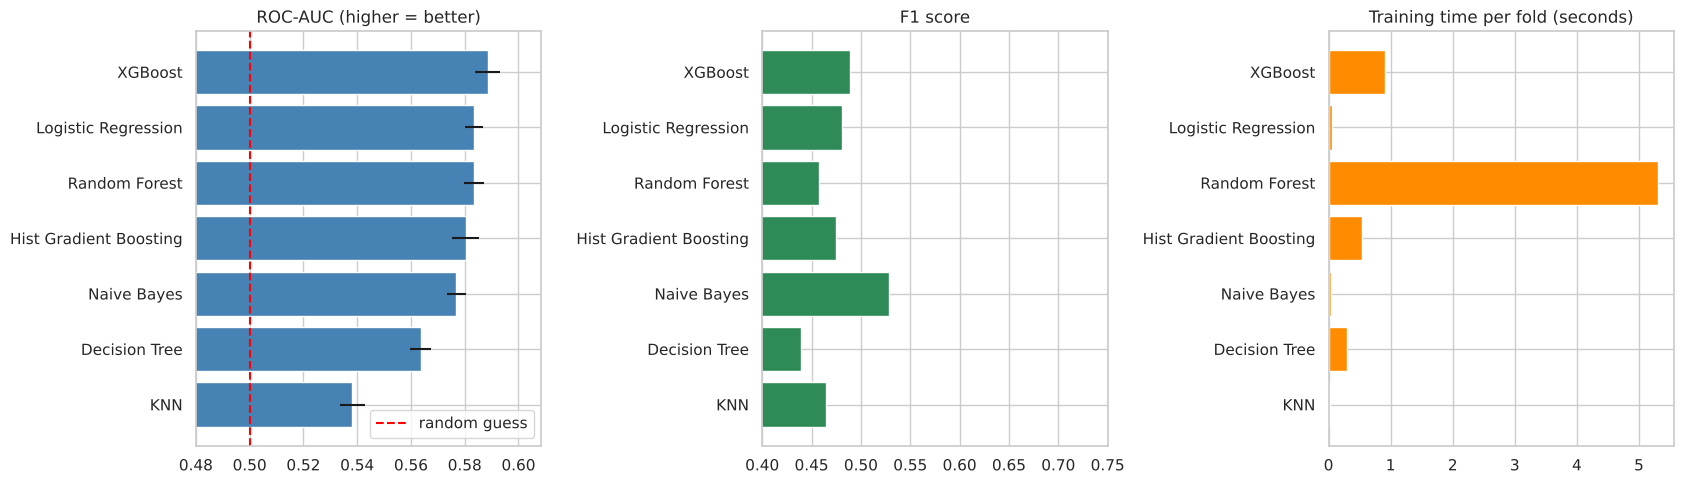

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(17, 5))
o = comp.sort_values('roc_auc').index
ax[0].barh(o, comp.loc[o, 'roc_auc'], xerr=comp.loc[o, 'roc_auc_std'], color='steelblue')
ax[0].axvline(0.5, color='red', ls='--', label='random guess'); ax[0].set_xlim(0.48, comp.roc_auc.max() + 0.02)
ax[0].set_title('ROC-AUC (higher = better)'); ax[0].legend()
ax[1].barh(o, comp.loc[o, 'f1'], color='seagreen'); ax[1].set_title('F1 score'); ax[1].set_xlim(0.4, 0.75)
ax[2].barh(o, comp.loc[o, 'fit_time'], color='darkorange'); ax[2].set_title('Training time per fold (seconds)')
plt.tight_layout(); plt.show()

**Interpretation**
- **XGBoost** is on top (AUC ≈ 0.588), but Logistic Regression, Random Forest and Hist Gradient Boosting are within 0.01. The fold-to-fold spread (±0.005) is about as large as the gaps, so these four are **practically tied**.
- **KNN** is clearly worst (AUC ≈ 0.54): distance-based methods struggle when many features each carry only a little signal.
- **Naive Bayes** has the best F1 (0.53) because it predicts "Returned" more often, which raises recall.
- Random Forest is the slowest; XGBoost and Logistic Regression are fast.

## 4. Did Feature Engineering Help?

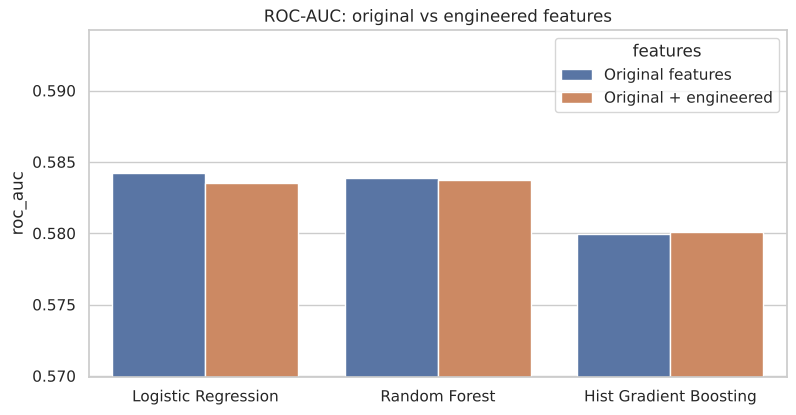

features,Original + engineered,Original features
model,,
Hist Gradient Boosting,0.5801,0.5800
Logistic Regression,0.5836,0.5842
Random Forest,0.5837,0.5839


In [6]:
engineered = ['price_after_discount', 'log_price', 'views_per_minute', 'expected_returns',
              'is_late_delivery', 'high_return_customer'] + [c for c in feature_names if c.startswith('age_group_')]
orig_cols = [c for c in feature_names if c not in engineered]

rows = []
for name in ['Logistic Regression', 'Random Forest', 'Hist Gradient Boosting']:
    for label, cols in [('Original features', orig_cols), ('Original + engineered', feature_names)]:
        auc = cross_val_score(clone(get_models()[name]), X_s[cols], y_s, cv=3, scoring='roc_auc').mean()
        rows.append({'model': name, 'features': label, 'roc_auc': auc})
fe = pd.DataFrame(rows)

plt.figure(figsize=(9, 4.5))
sns.barplot(data=fe, x='model', y='roc_auc', hue='features')
plt.ylim(fe.roc_auc.min() - 0.01, fe.roc_auc.max() + 0.01); plt.title('ROC-AUC: original vs engineered features')
plt.xlabel(''); plt.show()
fe.pivot(index='model', columns='features', values='roc_auc').round(4)

**Interpretation**
- Engineered features changed AUC by less than **0.001** for all three models, which is no real gain.
- This is still a valid finding for the report: the models already capture these relationships from the original columns.
- The features stay in the pipeline because they are harmless and are already wired into FastAPI, but we do not claim they improved accuracy.

## 5. Hyperparameter Tuning (top 2 models)

In [7]:
param_grids = {
    'Logistic Regression': {'C': np.logspace(-3, 2, 20)},
    'Decision Tree': {'max_depth': [3, 4, 5, 6, 8, 10], 'min_samples_leaf': [20, 50, 100, 200],
                      'criterion': ['gini', 'entropy']},
    'Random Forest': {'n_estimators': [100, 200], 'max_depth': [8, 10, 12, 16],
                      'min_samples_leaf': [10, 20, 50], 'max_features': ['sqrt', 0.5]},
    'Hist Gradient Boosting': {'learning_rate': [0.02, 0.05, 0.1], 'max_iter': [100, 200, 300],
                               'max_depth': [None, 3, 5], 'min_samples_leaf': [20, 50, 100],
                               'l2_regularization': [0, 1, 10]},
    'XGBoost': {'n_estimators': [100, 200, 300], 'max_depth': [3, 4, 5, 6], 'learning_rate': [0.02, 0.05, 0.1],
                'subsample': [0.7, 0.9], 'colsample_bytree': [0.6, 0.8, 1.0], 'min_child_weight': [1, 5, 10]}}

to_tune = [n for n in comp.index if n in param_grids][:2]
print('Tuning:', to_tune)

searches, default_auc = {}, {}
for name in to_tune:
    s = RandomizedSearchCV(get_models()[name], param_grids[name], n_iter=8, cv=3, scoring='roc_auc',
                           random_state=RS, n_jobs=-1)
    s.fit(X_s, y_s)
    searches[name] = s
    default_auc[name] = cross_val_score(clone(get_models()[name]), X_s, y_s, cv=3, scoring='roc_auc').mean()
    print(f'{name}: default={default_auc[name]:.4f} -> tuned={s.best_score_:.4f}')
    print('   best params:', s.best_params_)

Tuning: ['XGBoost', 'Logistic Regression']


XGBoost: default=0.5850 -> tuned=0.5886
   best params: {'subsample': 0.7, 'n_estimators': 300, 'min_child_weight': 10, 'max_depth': 3, 'learning_rate': 0.02, 'colsample_bytree': 1.0}


Logistic Regression: default=0.5836 -> tuned=0.5836
   best params: {'C': np.float64(29.763514416313193)}


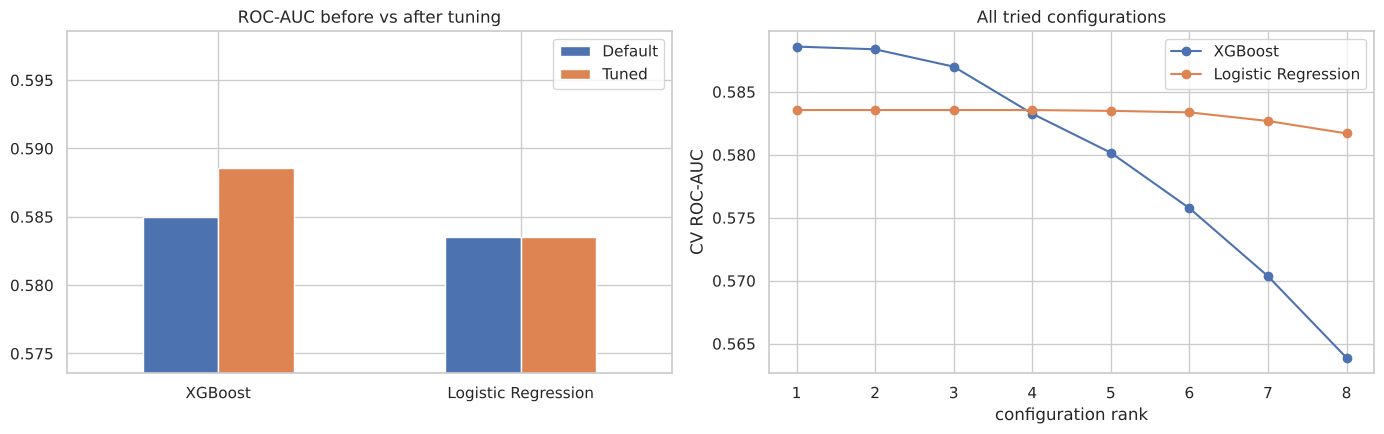

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
tuned_cmp = pd.DataFrame({'Default': default_auc, 'Tuned': {n: s.best_score_ for n, s in searches.items()}})
tuned_cmp.plot(kind='bar', ax=ax[0], rot=0); ax[0].set_ylim(tuned_cmp.min().min() - 0.01, tuned_cmp.max().max() + 0.01)
ax[0].set_title('ROC-AUC before vs after tuning')
for n, s in searches.items():
    r = pd.DataFrame(s.cv_results_).sort_values('rank_test_score')
    ax[1].plot(range(1, len(r) + 1), r.mean_test_score.values, marker='o', label=n)
ax[1].set_xlabel('configuration rank'); ax[1].set_ylabel('CV ROC-AUC'); ax[1].set_title('All tried configurations'); ax[1].legend()
plt.tight_layout(); plt.show()

**Interpretation**
- The two best models, **XGBoost** and **Logistic Regression**, were tuned.
- XGBoost improved from 0.585 to about 0.589 (small gain). Logistic Regression did not change, so its regularization strength does not matter here.
- The best XGBoost settings are shallow and slow (`max_depth=3`, `learning_rate=0.02`, many trees): the data is noisy, so a **simple, cautious** model works best.

## 6. Train Final Versions on Full Training Data
Every model is trained on the full train set (KNN uses the 40k sample because it is slow on big data), then scored **once** on the untouched test set. These results feed the GUI comparison page.

In [9]:
results, trained, probas = {}, {}, {}

def simple_params(m):
    return {k: v for k, v in m.get_params().items() if isinstance(v, (int, float, str, bool, type(None)))}

def register(name, model, kind, cv_auc, params, X_fit, y_fit):
    t = time.time(); model.fit(X_fit, y_fit); ft = time.time() - t
    results[name] = {'kind': kind, 'fit_time_sec': round(ft, 2), 'cv_roc_auc': float(cv_auc), 'params': params,
                     'trained_on_rows': len(X_fit), 'train': evaluate(model, X_fit, y_fit),
                     'test': evaluate(model, X_test, y_test)}
    trained[name] = model
    probas[name] = model.predict_proba(X_test)[:, 1]
    print(f"{name:32s} test AUC={results[name]['test']['roc_auc']:.4f}  ({ft:.1f}s)")

for name, m in get_models().items():
    Xf, yf = (X_s, y_s) if name == 'KNN' else (X_train, y_train)
    register(name, m, 'base', comp.loc[name, 'roc_auc'], simple_params(m), Xf, yf)

for name, s in searches.items():
    m = clone(s.best_estimator_)
    register(f'{name} (tuned)', m, 'tuned', s.best_score_, s.best_params_, X_train, y_train)

Logistic Regression              test AUC=0.5886  (0.2s)


Naive Bayes                      test AUC=0.5799  (0.1s)


KNN                              test AUC=0.5350  (0.0s)


Decision Tree                    test AUC=0.5753  (1.6s)


Random Forest                    test AUC=0.5925  (31.1s)


Hist Gradient Boosting           test AUC=0.5922  (3.4s)


XGBoost                          test AUC=0.5954  (3.3s)


XGBoost (tuned)                  test AUC=0.5931  (4.8s)


Logistic Regression (tuned)      test AUC=0.5886  (0.2s)


In [10]:
rows = {n: {**{f'test_{k}': v for k, v in r['test'].items()}, 'train_auc': r['train']['roc_auc'],
            'cv_auc': r['cv_roc_auc'], 'fit_time': r['fit_time_sec']} for n, r in results.items()}
res_df = pd.DataFrame(rows).T.sort_values('test_roc_auc', ascending=False)
res_df.round(3).style.background_gradient(cmap='YlGn', subset=['test_accuracy', 'test_f1', 'test_roc_auc'])

,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc,train_auc,cv_auc,fit_time
XGBoost,0.571000,0.561000,0.435000,0.490000,0.595000,0.614000,0.588000,3.260000
XGBoost (tuned),0.570000,0.565000,0.408000,0.474000,0.593000,0.599000,0.589000,4.830000
Random Forest,0.570000,0.565000,0.405000,0.472000,0.593000,0.702000,0.583000,31.110000
Hist Gradient Boosting,0.568000,0.557000,0.438000,0.490000,0.592000,0.635000,0.580000,3.360000
Logistic Regression,0.566000,0.554000,0.432000,0.486000,0.589000,0.588000,0.583000,0.240000
Logistic Regression (tuned),0.566000,0.554000,0.432000,0.486000,0.589000,0.588000,0.584000,0.240000
Naive Bayes,0.558000,0.536000,0.511000,0.523000,0.580000,0.580000,0.577000,0.130000
Decision Tree,0.556000,0.549000,0.365000,0.439000,0.575000,0.585000,0.564000,1.590000
KNN,0.528000,0.503000,0.425000,0.461000,0.535000,0.642000,0.538000,0.010000


**Interpretation**
- On the untouched test set all good models score **AUC ≈ 0.59** and accuracy ≈ 0.57. KNN (0.535) is the weakest.
- Test scores are close to the cross-validation scores, so the estimates are reliable.
- Default XGBoost (0.595) is slightly above the tuned one (0.593). That gap is within noise. We pick the final model by **cross-validation**, not by test score, to keep the test set honest. The final model is **XGBoost (tuned)**.
- Low scores are expected here: the data has weak signal, so even the best model is only moderately better than guessing.

## 7. Overfitting Check

Final model: XGBoost (tuned)


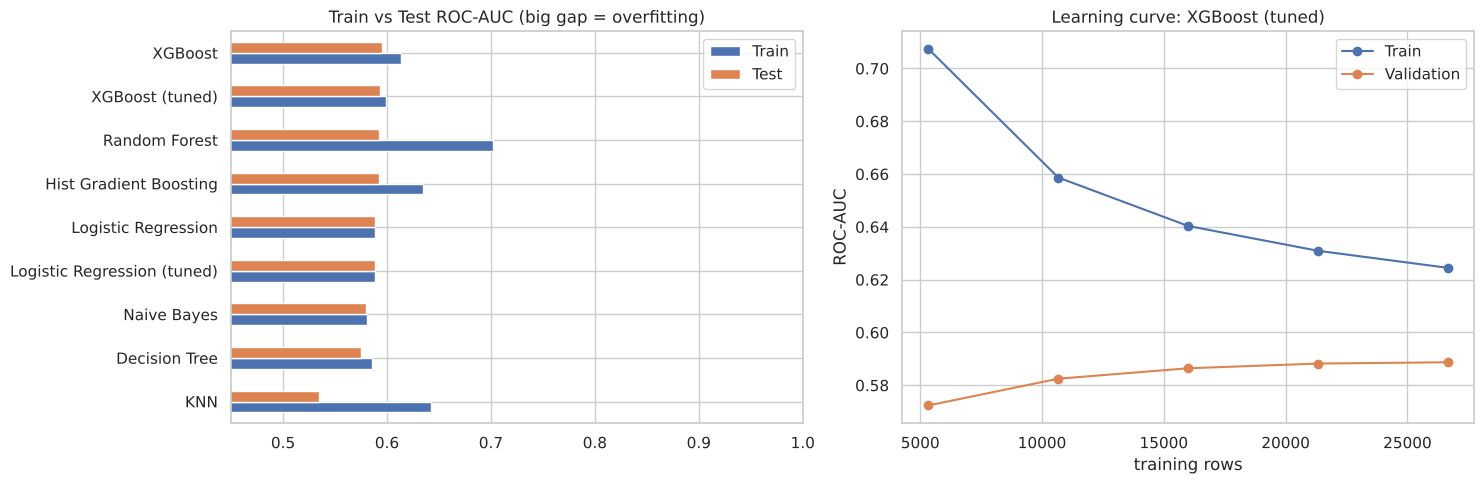

In [11]:
# Choose the final model by CROSS-VALIDATION score (not by test score)
tuned_scores = {n: r['cv_roc_auc'] for n, r in results.items() if r['kind'] == 'tuned'}
final_name = max(tuned_scores, key=tuned_scores.get) if tuned_scores else comp.index[0]
final_model = trained[final_name]
print('Final model:', final_name)

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
g = pd.DataFrame({'Train': {n: r['train']['roc_auc'] for n, r in results.items()},
                  'Test': {n: r['test']['roc_auc'] for n, r in results.items()}}).sort_values('Test')
g.plot(kind='barh', ax=ax[0]); ax[0].set_xlim(0.45, 1.0); ax[0].set_title('Train vs Test ROC-AUC (big gap = overfitting)')

sizes, tr, va = learning_curve(clone(final_model), X_s, y_s, cv=3, scoring='roc_auc',
                               train_sizes=np.linspace(0.2, 1.0, 5), random_state=RS)
ax[1].plot(sizes, tr.mean(1), marker='o', label='Train'); ax[1].plot(sizes, va.mean(1), marker='o', label='Validation')
ax[1].set_xlabel('training rows'); ax[1].set_ylabel('ROC-AUC'); ax[1].set_title(f'Learning curve: {final_name}'); ax[1].legend()
plt.tight_layout(); plt.show()

**Interpretation**
- **Random Forest** (train 0.70 vs test 0.59), **KNN** (0.64 vs 0.54) and default Hist Gradient Boosting (0.64 vs 0.59) are **overfitting**: they memorize training noise.
- The **final XGBoost (tuned)** has almost no gap (0.60 vs 0.59), so it generalizes well.
- Learning curve: the validation line rises slowly and flattens near 0.59 while the train line falls toward it. More rows would give **only a small gain**. Better features would matter more.

## 8. Final Model Evaluation on the Test Set

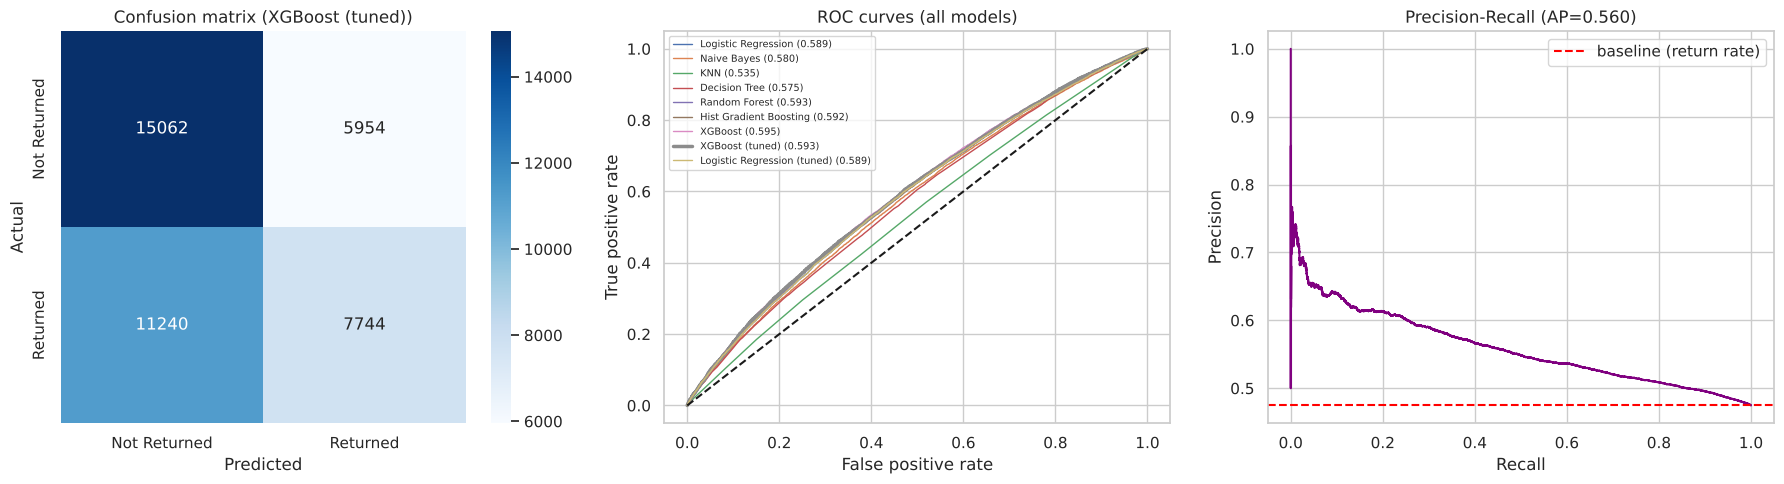

accuracy     0.5702
precision    0.5653
recall       0.4079
f1           0.4739
roc_auc      0.5931


In [12]:
p = probas[final_name]
pred = (p >= 0.5).astype(int)
cm = confusion_matrix(y_test, pred)

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax[0], xticklabels=['Not Returned', 'Returned'],
            yticklabels=['Not Returned', 'Returned'])
ax[0].set_title(f'Confusion matrix ({final_name})'); ax[0].set_xlabel('Predicted'); ax[0].set_ylabel('Actual')

for n, pr in probas.items():                       # ROC of all models
    f, t, _ = roc_curve(y_test, pr)
    ax[1].plot(f, t, lw=2.5 if n == final_name else 1, label=f"{n} ({roc_auc_score(y_test, pr):.3f})")
ax[1].plot([0, 1], [0, 1], 'k--'); ax[1].set_title('ROC curves (all models)')
ax[1].set_xlabel('False positive rate'); ax[1].set_ylabel('True positive rate'); ax[1].legend(fontsize=7)

pr_, rc_, _ = precision_recall_curve(y_test, p)
ax[2].plot(rc_, pr_, color='purple'); ax[2].axhline(y_test.mean(), color='red', ls='--', label='baseline (return rate)')
ax[2].set_title(f'Precision-Recall (AP={average_precision_score(y_test, p):.3f})')
ax[2].set_xlabel('Recall'); ax[2].set_ylabel('Precision'); ax[2].legend()
plt.tight_layout(); plt.show()
print(pd.Series(results[final_name]['test']).round(4).to_string())

**Interpretation**
- At the default 0.5 cutoff the model is right about 57% of the time. Of orders predicted "Returned", about 57% really were returned (precision), but it catches only about 41% of the real returns (recall).
- The ROC curves of the good models are almost on top of each other, and all are above the diagonal (random guess) by a small margin.
- The precision-recall curve stays slightly above the red baseline (the overall return rate), which confirms the model has a modest but real ranking ability.

## 9. Threshold Tuning (0.5 is not always best)

Chosen threshold: 0.48


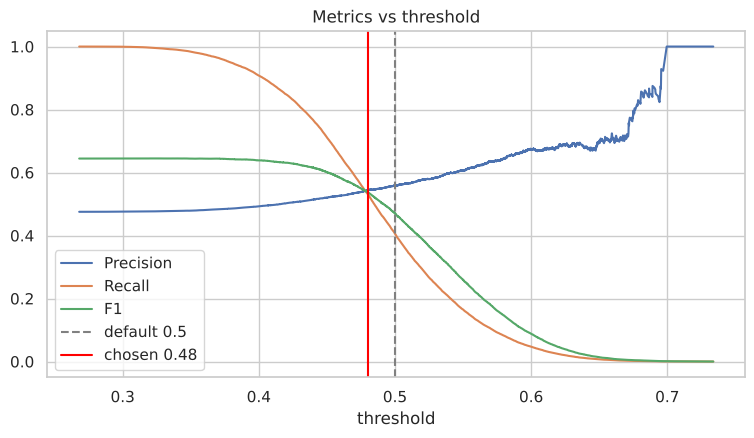

,accuracy,precision,recall,f1,roc_auc
threshold 0.5,0.5702,0.5653,0.4079,0.4739,0.5931
threshold 0.48,0.5655,0.5433,0.5296,0.5364,0.5931


In [13]:
# Use out-of-fold probabilities on training data (NOT the test set) to pick the threshold
oof = cross_val_predict(clone(final_model), X_s, y_s, cv=3, method='predict_proba')[:, 1]
fpr, tpr, thr = roc_curve(y_s, oof)
best_thr = float(thr[np.argmax(tpr - fpr)])          # Youden's J: best balance of TPR and FPR
print('Chosen threshold:', round(best_thr, 3))

pr_, rc_, th_ = precision_recall_curve(y_s, oof)
f1_ = 2 * pr_ * rc_ / (pr_ + rc_ + 1e-9)
plt.figure(figsize=(9, 4.5))
plt.plot(th_, pr_[:-1], label='Precision'); plt.plot(th_, rc_[:-1], label='Recall'); plt.plot(th_, f1_[:-1], label='F1')
plt.axvline(0.5, color='gray', ls='--', label='default 0.5'); plt.axvline(best_thr, color='red', label=f'chosen {best_thr:.2f}')
plt.xlabel('threshold'); plt.title('Metrics vs threshold'); plt.legend(); plt.show()

cmp_thr = pd.DataFrame({'threshold 0.5': evaluate(final_model, X_test, y_test, 0.5),
                        f'threshold {best_thr:.2f}': evaluate(final_model, X_test, y_test, best_thr)}).T
cmp_thr.round(4)

**Interpretation**
- Lowering the cutoff from 0.5 to about **0.48** raises recall from 0.41 to 0.53 (we catch many more returns) and F1 from 0.47 to 0.54. Precision and accuracy drop slightly.
- ROC-AUC does not change, because the model's ranking is the same; only the label cutoff moves.
- The threshold was chosen on **training-set predictions**, not on the test set. A business that cares more about catching returns can lower it further.

## 10. Explainability

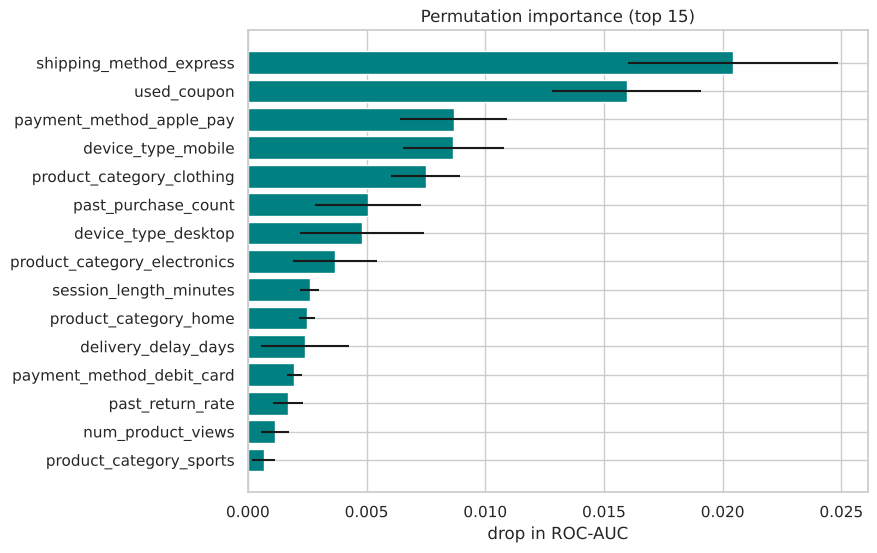

In [14]:
# Permutation importance: how much does AUC drop when a feature is shuffled? (on a test sample)
ti = X_test.sample(5000, random_state=RS).index
pi = permutation_importance(final_model, X_test.loc[ti], y_test.loc[ti], scoring='roc_auc',
                            n_repeats=5, random_state=RS)
imp = pd.DataFrame({'importance': pi.importances_mean, 'std': pi.importances_std}, index=feature_names)
top = imp.sort_values('importance').tail(15)
plt.figure(figsize=(8, 6))
plt.barh(top.index, top.importance, xerr=top['std'], color='teal')
plt.title('Permutation importance (top 15)'); plt.xlabel('drop in ROC-AUC'); plt.show()

**Interpretation**
- The most important features are **express shipping** and **used coupon**, followed by Apple Pay, mobile device and the clothing category.
- Each bar is small (a drop of at most 0.02 AUC), which again shows that the signal is spread thinly across many features.
- The engineered features do not appear at the top, matching the earlier check.

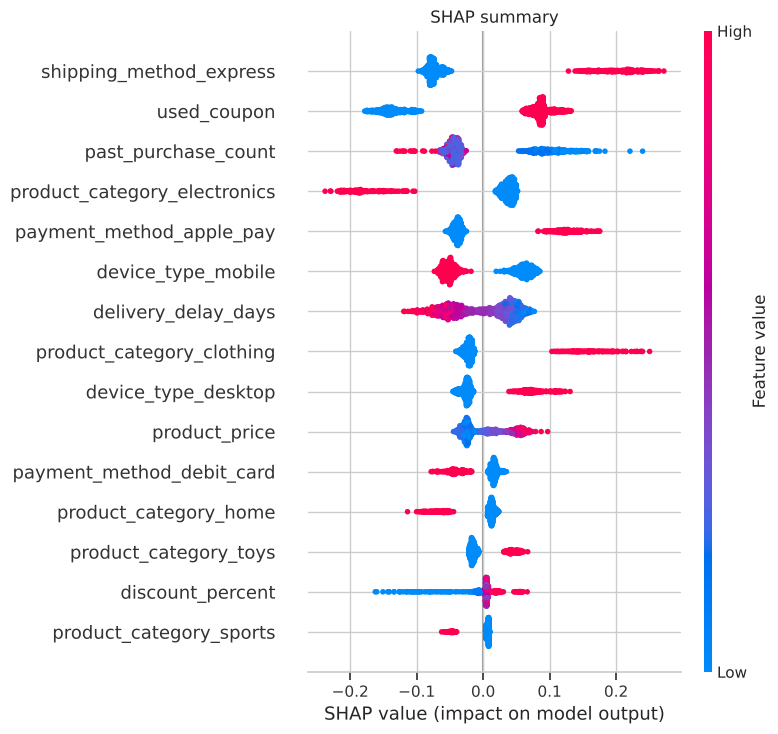

In [15]:
# SHAP: direction and size of each feature's effect
shap_imp = None
if HAS_SHAP:
    Xs = X_test.loc[ti].iloc[:1000]
    try:
        sv = shap.TreeExplainer(final_model).shap_values(Xs)
        sv = sv[1] if isinstance(sv, list) else (sv[:, :, 1] if np.ndim(sv) == 3 else sv)
    except Exception:
        bg = X_train.sample(100, random_state=RS)
        sv = shap.Explainer(lambda d: final_model.predict_proba(d)[:, 1], shap.maskers.Independent(bg))(Xs.iloc[:200]).values
        Xs = Xs.iloc[:200]
    shap_imp = pd.Series(np.abs(sv).mean(0), index=feature_names).sort_values(ascending=False)
    shap.summary_plot(sv, Xs, max_display=15, show=False); plt.title('SHAP summary'); plt.tight_layout(); plt.show()
else:
    print('Install shap to see this plot:  pip install shap')

**Interpretation**
- SHAP agrees with permutation importance: **express shipping**, **used coupon**, **past purchase count**, **electronics category**, **Apple Pay** and **mobile device** have the largest effects.
- Reading the plot: each dot is an order. Red = high feature value, and dots to the right push the prediction toward "Returned". For example, using a coupon and express shipping push the risk up, while electronics and more past purchases push it down.

## 11. Save Models & GUI Files

In [16]:
def slug(n): return n.lower().replace(' (tuned)', '_tuned').replace(' ', '_')

# 1) every trained model
for n, m in trained.items():
    joblib.dump(m, f'models/{slug(n)}.joblib')
joblib.dump(final_model, 'models/final_model.joblib')

# 2) risk levels from out-of-fold probabilities (low / medium / high = three equal groups)
cut_lo, cut_hi = [float(x) for x in np.quantile(oof, [1/3, 2/3])]

def to_py(o):
    if isinstance(o, dict):  return {str(k): to_py(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [to_py(v) for v in o]
    if isinstance(o, pd.Series): return to_py(o.to_dict())
    if hasattr(o, 'tolist'): return o.tolist()
    if isinstance(o, np.generic): return o.item()
    return o
def save_json(obj, path):
    with open(path, 'w') as f: json.dump(to_py(obj), f, indent=2)

# 3) metrics for every model (comparison page)
for n in results: results[n]['model_file'] = f'models/{slug(n)}.joblib'
save_json(results, 'artifacts/model_results.json')

# 4) curves & confusion matrices (model-details page)
grid = np.linspace(0, 1, 101); curves = {}
for n, pr in probas.items():
    f, t, _ = roc_curve(y_test, pr)
    thr_n = best_thr if n == final_name else 0.5
    curves[n] = {'fpr': grid, 'tpr': np.interp(grid, f, t),
                 'confusion_matrix': confusion_matrix(y_test, (pr >= thr_n).astype(int)), 'cm_threshold': thr_n}
pp, rr, _ = precision_recall_curve(y_test, probas[final_name]); step = max(1, len(pp) // 200)
curves[final_name]['pr'] = {'precision': pp[::step], 'recall': rr[::step]}
save_json(curves, 'artifacts/curves.json')

# 5) feature importance (explainability page)
save_json({'permutation': imp.sort_values('importance', ascending=False).round(6).to_dict('index'),
           'shap_mean_abs': None if shap_imp is None else shap_imp.round(6).to_dict()}, 'artifacts/feature_importance.json')

# 6) final config for FastAPI
save_json({'final_model': final_name, 'model_file': 'models/final_model.joblib', 'threshold': best_thr,
           'default_threshold': 0.5, 'risk_cutoffs': {'low_max': cut_lo, 'medium_max': cut_hi},
           'feature_names': feature_names, 'test_metrics_default_threshold': results[final_name]['test'],
           'test_metrics_tuned_threshold': evaluate(final_model, X_test, y_test, best_thr)}, 'artifacts/final_config.json')
print('Saved:', sorted(os.listdir('models')))

Saved: ['decision_tree.joblib', 'final_model.joblib', 'hist_gradient_boosting.joblib', 'knn.joblib', 'logistic_regression.joblib', 'logistic_regression_tuned.joblib', 'naive_bayes.joblib', 'random_forest.joblib', 'xgboost.joblib', 'xgboost_tuned.joblib']


In [17]:
# 7) data summary for the GUI "Data insights" and "Workflow" pages
from features import clean, add_features
raw = pd.read_csv('train.csv')
fe_df = add_features(clean(raw))
num_cols = ['customer_age', 'product_price', 'discount_percent', 'product_rating', 'past_purchase_count',
            'past_return_rate', 'delivery_delay_days', 'session_length_minutes', 'num_product_views', 'used_coupon']
summary = {
    'rows': len(raw), 'columns': raw.shape[1], 'target_share': raw['returned'].value_counts(normalize=True).sort_index(),
    'impossible_values': {'price<=0': (raw.product_price <= 0).sum(), 'views<0': (raw.num_product_views < 0).sum(),
                          'session<0': (raw.session_length_minutes < 0).sum(), 'rating>5': (raw.product_rating > 5).sum()},
    'return_rate_by': {c: raw.groupby(c)['returned'].mean().round(4) for c in
                       ['device_type', 'product_category', 'shipping_method', 'payment_method', 'used_coupon']},
    'correlation_with_target': raw[num_cols + ['returned']].corr()['returned'].drop('returned').round(4),
    'engineered_features': engineered, 'final_feature_count': len(feature_names),
    'train_rows': len(X_train), 'test_rows': len(X_test),
    'workflow_steps': ['Raw data', 'Cleaning', 'Feature engineering', 'Train/test split', 'Impute + scale + encode',
                       'Baseline', 'Model comparison', 'Tuning', 'Final model + threshold', 'Explainability']}
save_json(summary, 'artifacts/data_summary.json')
print('Saved:', sorted(os.listdir('artifacts')))

Saved: ['curves.json', 'data_summary.json', 'feature_importance.json', 'final_config.json', 'model_results.json']


## 12. Test the Full Prediction Flow (what FastAPI will do)

In [18]:
preprocessor = joblib.load('preprocessor.joblib')
final_model_loaded = joblib.load('models/final_model.joblib')

def predict_order(order: dict):
    df = pd.DataFrame([order])
    Xp = preprocessor.transform(add_features(clean(df)))   # same cleaning + features + pipeline as training
    Xp.columns = feature_names
    p = float(final_model_loaded.predict_proba(Xp)[:, 1][0])
    level = 'Low' if p < cut_lo else 'Medium' if p < cut_hi else 'High'
    return {'return_probability': round(p, 3), 'prediction': int(p >= best_thr), 'risk_level': level}

order_a = {'customer_age': 30, 'product_price': 120.0, 'discount_percent': 55, 'product_rating': 3.2,
           'past_purchase_count': 2, 'past_return_rate': 0.5, 'delivery_delay_days': 0.0,
           'session_length_minutes': 20, 'num_product_views': 3, 'used_coupon': 1,
           'device_type': 'desktop', 'product_category': 'clothing', 'shipping_method': 'express',
           'payment_method': 'apple_pay'}
order_b = {**order_a, 'product_price': 15.0, 'discount_percent': 10, 'past_purchase_count': 15, 'past_return_rate': 0.1,
           'num_product_views': 25, 'session_length_minutes': 110, 'used_coupon': 0, 'device_type': 'mobile',
           'product_category': 'electronics', 'shipping_method': 'same_day', 'payment_method': 'debit_card'}
print('Order A:', predict_order(order_a))
print('Order B:', predict_order(order_b))

Order A: {'return_probability': 0.727, 'prediction': 1, 'risk_level': 'High'}
Order B: {'return_probability': 0.322, 'prediction': 0, 'risk_level': 'Low'}


**Interpretation**
- This is the exact path FastAPI will follow: raw order → cleaning → features → pipeline → model → probability, label and risk level.
- Order A (clothing, express, coupon, Apple Pay, high past return rate) gets a **high** return probability (~0.73).
- Order B (electronics, same-day, no coupon, many past purchases) gets a **low** one (~0.32).
- Risk levels are based on three equal groups of predicted probability: Low, Medium, High.

## 13. Summary
| Step | Result |
|---|---|
| Baseline | Logistic Regression AUC ≈ 0.58 (Dummy = 0.50) |
| Model comparison | XGBoost, Logistic Regression, Random Forest, HistGB are close; KNN is worst |
| Feature engineering | No measurable gain (< 0.001 AUC) |
| Tuning | Small gain for XGBoost (~0.004 AUC) |
| Final model | **XGBoost (tuned)**, test AUC ≈ 0.59, no overfitting |
| Threshold | ≈ 0.48 (better recall and F1 than 0.5) |
| Main drivers | Express shipping, coupon use, payment method, device, category, past purchases |
| Saved | `models/`, `artifacts/` (results, curves, importance, config, data summary) |

**Honest conclusion:** the dataset has weak signal, so the model is only moderately better than guessing. The value of the project is the full pipeline, the fair comparison, and the risk **ranking** of orders.

➡️ Next: **FastAPI backend (`app.py`)** and the **GUI**.